El flujo natural en ciencia de datos es: preparar datos con Pandas y graficar con Seaborn. Acá verás cómo:

Usar DataFrames directamente en Seaborn (formato tidy/long).
Combinar filtros de Pandas con gráficos “dinámicos” (funciones/params) para explorar sin Jupyter, tal como venimos trabajando en VS Code.
Todos los ejemplos incluyen imports y set_theme para copiar/pegar y ejecutar.

8.1 Usar DataFrames directamente en Seaborn
Seaborn “entiende” un DataFrame: le pasás data=df y los nombres de columna (strings) para x, y, hue, etc. No tenés que separar series manualmente.

A) Scatter con data=df y nombres de columnas (tips)

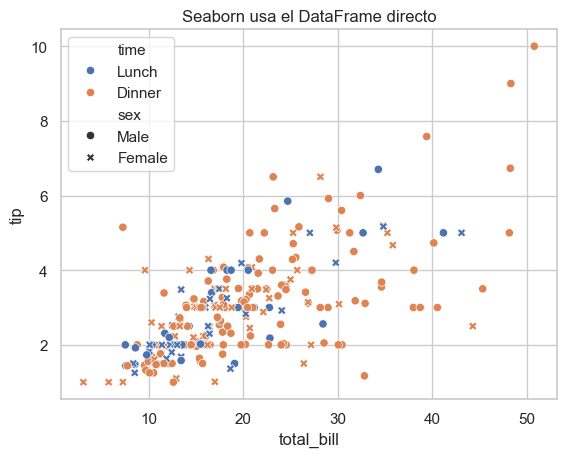

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

tips = sns.load_dataset("tips")
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", style="sex")
plt.title("Seaborn usa el DataFrame directo")
plt.show()

B) Resumen con groupby + reset_index() → barplot

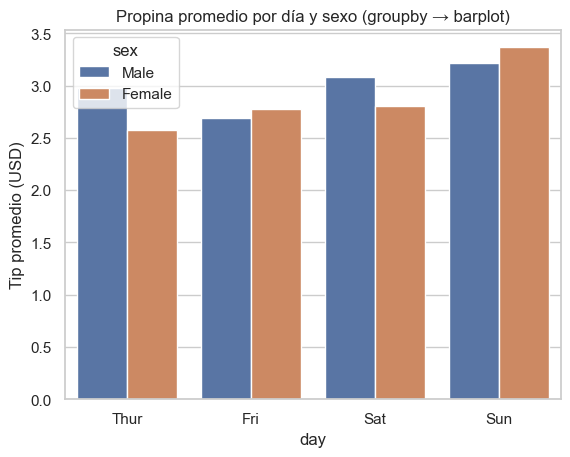

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")

tips = sns.load_dataset("tips")

# Promedio de propina por día y sexo
resumen = (
    tips.groupby(["day", "sex"], as_index=False)["tip"]
        .mean()
        .rename(columns={"tip": "tip_mean"})
)

sns.barplot(data=resumen, x="day", y="tip_mean", hue="sex", errorbar=None)
plt.title("Propina promedio por día y sexo (groupby → barplot)")
plt.ylabel("Tip promedio (USD)")
plt.show()

C) Wide → Long: melt para graficar varias columnas numéricas en un solo lineplot

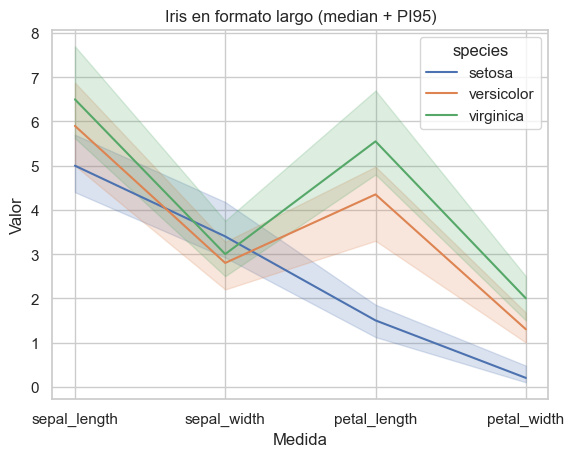

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")

iris = sns.load_dataset("iris")

# Pasar de columnas separadas a formato largo (long/tidy)
iris_long = iris.melt(
    id_vars="species",
    value_vars=["sepal_length", "sepal_width", "petal_length", "petal_width"],
    var_name="feature",
    value_name="value"
)

sns.lineplot(data=iris_long, x="feature", y="value", hue="species", estimator="median", errorbar=("pi", 95))
plt.title("Iris en formato largo (median + PI95)")
plt.xlabel("Medida")
plt.ylabel("Valor")
plt.show()